In [1]:
import pandas as pd
import numpy as np
import torch 
import os
import json

from darts import TimeSeries, concatenate
from darts.utils.callbacks import TFMProgressBar
from darts.metrics import mape, smape, mse, rmse, mae, mql, ql
from darts.dataprocessing.transformers import Scaler
from darts.dataprocessing.transformers import StaticCovariatesTransformer
from sklearn.preprocessing import MinMaxScaler
import optuna
from optuna.samplers import TPESampler
from optuna.storages import JournalStorage
from optuna.storages.journal import JournalFileBackend
from darts.models import (
    RandomForestModel,
    LinearRegressionModel,
    XGBModel,
    TFTModel,
    TiDEModel
)
from darts.utils.likelihood_models import GaussianLikelihood, PoissonLikelihood, QuantileRegression
import matplotlib.pyplot as plt
from pytorch_lightning.callbacks import Callback, EarlyStopping
import pickle
import helpers as hp

torch.set_float32_matmul_precision("medium")
pd.options.mode.copy_on_write = True
include_stringency_index = False
accel = "gpu"

quantiles = [0.01, 0.025, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 0.975, 0.99]

In [2]:
#n_optuna_trials = 4
gpu_id = 0
tuning_name = "Tuning_30_07_2025" #Name of the tuning scenario to use
random_seed = 20

#We define a boolean here, relevant to model evaluation
#If this is true, then we train a model with the tuned hyperparameters from scratch - i.e. using train1, 2, and 3. This also means that
#we can train a separate scaler on train1, which is then applied to train 1,2,3
#If this is false, then we mirror the tuning process first, training on 1a,b,c then the model will be fine tuned using train 1,2,3.
#This means that we apply the same scaler, trained only on train1a to train1a,b,c and train1,2,3. 
train_from_scratch = False
global_fit = False
use_multi_climate_final_targ = False

base_dir = os.getcwd()
model_input_dir = os.path.join(base_dir, "ModelInput_Round2")
tuning_dir = os.path.join(base_dir, "Dengue Tuning", tuning_name)
vis_output_dir = os.path.join(tuning_dir, "Results_Round2")
climate_tuning_dir = os.path.join(base_dir, "Climate Tuning_Round2", "Notebook_24_07_2025")
climate_model_name = "RandomForest"
climate_forecast_dir = os.path.join(climate_tuning_dir, climate_model_name, "Forecasts_Round2")

os.makedirs(tuning_dir, exist_ok = True)
os.makedirs(vis_output_dir, exist_ok = True)
weekly_cal = pd.read_csv(os.path.join(model_input_dir, "Calendar.csv"))
weekly_cal = weekly_cal.iloc[1:]
climate_df = pd.read_csv(os.path.join(model_input_dir, "TimeVaryingCovs.csv"))
dengue_df = pd.read_csv(os.path.join(model_input_dir, "DengueCases.csv"))

#Remove uf = "ES" since there is no dengue data for Espirito Santo
climate_df = climate_df[climate_df["uf"] != "ES"]
dengue_df = dengue_df[dengue_df["uf"] != "ES"]

dengue_df = dengue_df[["epiweek", "Year", "Week", "uf", "uf_name", "Cases"]]

In [3]:
set_info = weekly_cal[["epiweek", "Year", "Week", "WeekStart", "WeekMid", "WeekEnd"]]

#Set up all the set information for splitting the dengue and climate data

#For tuning training 1a,b,c - val1a,b,c
set_info["den_train1a"] = set_info["epiweek"] <= 201825
set_info["den_train1b"] = set_info["epiweek"] <= 201925
set_info["den_train1c"] = set_info["epiweek"] <= 202025

set_info["den_gap1a"] = (set_info["epiweek"] >= 201826) & (set_info["epiweek"] <= 201840)
set_info["den_gap1b"] = (set_info["epiweek"] >= 201926) & (set_info["epiweek"] <= 201940)
set_info["den_gap1c"] = (set_info["epiweek"] >= 202026) & (set_info["epiweek"] <= 202040)

set_info["den_val1a"] = (set_info["epiweek"] >= 201841) & (set_info["epiweek"] <= 201940)
set_info["den_val1b"] = (set_info["epiweek"] >= 201941) & (set_info["epiweek"] <= 202040)
set_info["den_val1c"] = (set_info["epiweek"] >= 202041) & (set_info["epiweek"] <= 202140)

set_info["den_ex"] = (set_info["epiweek"] >= 202141) & (set_info["epiweek"] <= 202225)

#Train - Val - Test for model evaluation
set_info["den_train1"] = set_info["epiweek"] <= 202110
set_info["den_train2"] = set_info["epiweek"] <= 202210
set_info["den_train3"] = set_info["epiweek"] <= 202310
set_info["den_train4"] = set_info["epiweek"] <= 202410 #For fine-tuning the model for the 2nd round

set_info["den_gap1"] = (set_info["epiweek"] >= 202111) & (set_info["epiweek"] <= 202125)
set_info["den_gap2"] = (set_info["epiweek"] >= 202211) & (set_info["epiweek"] <= 202225)
set_info["den_gap3"] = (set_info["epiweek"] >= 202311) & (set_info["epiweek"] <= 202325)
set_info["den_gap4"] = (set_info["epiweek"] >= 202411) & (set_info["epiweek"] <= 202425)

set_info["den_val1"] = (set_info["epiweek"] >= 202126) & (set_info["epiweek"] <= 202225)
set_info["den_val2"] = (set_info["epiweek"] >= 202226) & (set_info["epiweek"] <= 202325)
set_info["den_val3"] = (set_info["epiweek"] >= 202326) & (set_info["epiweek"] <= 202425)
set_info["den_val4"] = (set_info["epiweek"] >= 202426) & (set_info["epiweek"] <= 202525)

#Hold sets - can be used to retrieve climate covariates for evaluation time
set_info["den_hold1"] = set_info["epiweek"] <= 202225
set_info["den_hold2"] = set_info["epiweek"] <= 202325
set_info["den_hold3"] = set_info["epiweek"] <= 202425
set_info["den_hold4"] = set_info["epiweek"] <= 202525

#Targets for model evaluation
set_info["den_targ1"] = (set_info["epiweek"] >= 202241) & (set_info["epiweek"] <= 202340)
set_info["den_targ2"] = (set_info["epiweek"] >= 202341) & (set_info["epiweek"] <= 202440)
set_info["den_targ3"] = (set_info["epiweek"] >= 202441) & (set_info["epiweek"] <= 202540)
set_info["den_targ4"] = (set_info["epiweek"] >= 202541) & (set_info["epiweek"] <= 202640)


In [4]:
uf_list = climate_df["uf"].unique()
uf_mapper = climate_df[["uf", "uf_name"]].copy().drop_duplicates()
uf_dict = dict(zip(uf_mapper["uf"], uf_mapper["uf_name"]))
uf_name_list = [uf_dict[curr_uf] for curr_uf in uf_list]

In [5]:
#Log transformed climate (just the precipitation columns)
log_trans_cols = ["precip_min", "precip_med", "precip_max"]
proc_climate_df = hp.transform_df_cols(climate_df, log_trans_cols, np.log1p)

#Log transformed dengue cases
proc_dengue_df = hp.transform_df_cols(dengue_df, ["Cases"], np.log1p)

In [6]:
#Create all the TimeSeries objects we need for tuning first
group_col = "uf"

#Dengue case TimeSeries - without any log transforms - mostly here for visualisations and loss computations
train1a = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1a")
train1b = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1b")
train1c = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1c")

val1a = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1a")
val1b = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1b")
val1c = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1c")

train1 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1")
train2 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train2")
train3 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train3")
train4 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train4")

val1 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1")
val2 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val2")
val3 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val3")
val4 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val4")

hold1 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold1")
hold2 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold2")
hold3 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold3")
hold4 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold4")

targ1 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_targ1")
targ2 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_targ2")
targ3 = hp.create_ts_list(dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_targ3")




#Log transformed version of the cases TimeSeries for actual training
train1a_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1a")
train1b_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1b")
train1c_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1c")

gap1a_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_gap1a")
gap1b_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_gap1b")
gap1c_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_gap1c")

val1a_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1a")
val1b_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1b")
val1c_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1c")


#Evaluation sets
train1_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train1")
train2_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train2")
train3_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train3")
train4_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_train4")

gap1_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_gap1")
gap2_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_gap2")
gap3_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_gap3")
gap4_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_gap4")

val1_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val1")
val2_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val2")
val3_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val3")
val4_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_val4")

hold1_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold1")
hold2_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold2")
hold3_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold3")
hold4_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_hold4")

targ1_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_targ1")
targ2_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_targ2")
targ3_log = hp.create_ts_list(proc_dengue_df, ["Cases"], group_col, uf_list, set_info = set_info, set_column = "den_targ3")

In [7]:
#Read the forecast results, two versions MultiClimate True or False
forecasts_multi_climate = hp.load_pickle(os.path.join(vis_output_dir, "Targ_GlobalFit=False_TrainFromScratch=False_MultiClimate=True.pkl"))
forecasts_single_climate = hp.load_pickle(os.path.join(vis_output_dir, "Targ_GlobalFit=False_TrainFromScratch=False_MultiClimate=False.pkl"))

val_forecasts_multi_climate = hp.load_pickle(os.path.join(vis_output_dir, "Val_GlobalFit=False_TrainFromScratch=False_MultiClimate=True.pkl"))
val_forecasts_single_climate = hp.load_pickle(os.path.join(vis_output_dir, "Val_GlobalFit=False_TrainFromScratch=False_MultiClimate=False.pkl"))


In [8]:
targ4_preds_multi = forecasts_multi_climate["targ4_preds"]
targ4_preds_single = forecasts_single_climate["targ4_preds"]

val4_preds_multi = val_forecasts_multi_climate["val4_preds"]
val4_preds_single = val_forecasts_single_climate["val4_preds"]

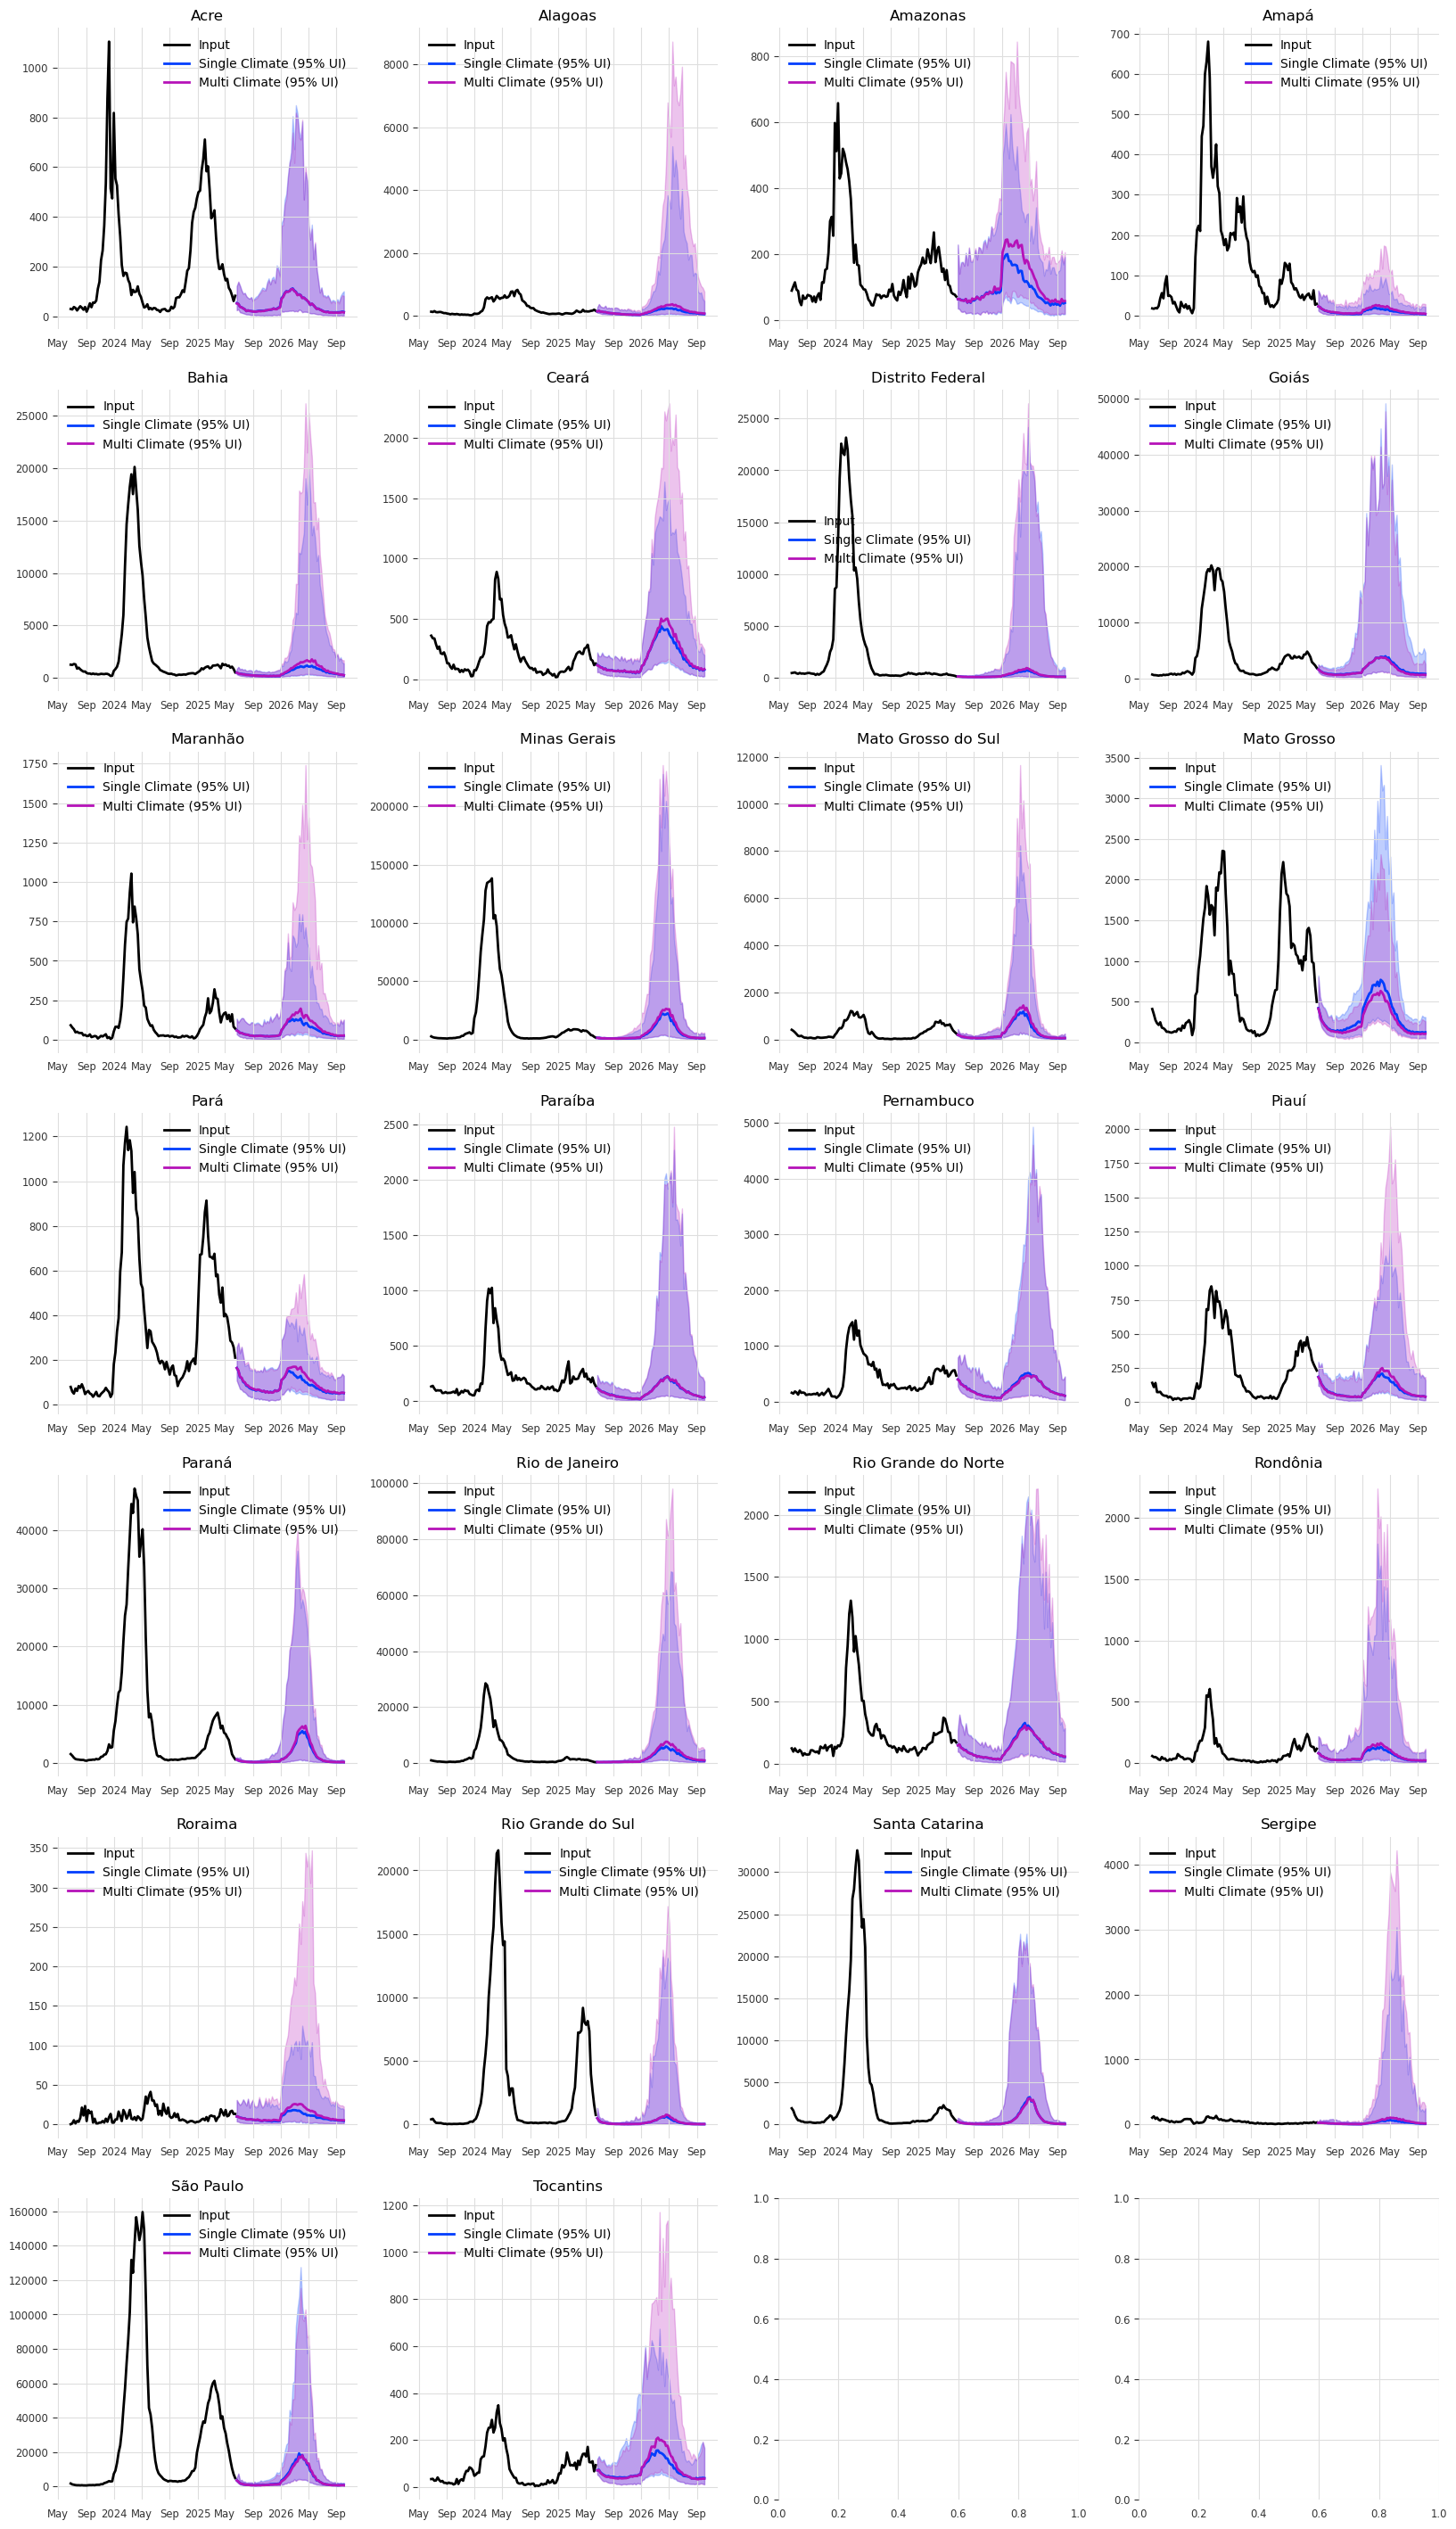

In [9]:
#Generate visuals of the Target 4 forecasts
targ4_dict_list = hp.create_ts_dict_list([hold4,  targ4_preds_single, targ4_preds_multi], 
                    ["Input", "Single Climate (95% UI)", "Multi Climate (95% UI)"], uf_name_list, comp_name = None)
targ4_plot = hp.plot_dict_list(targ4_dict_list, limit_dict = {"Input": 104})
plt.savefig(os.path.join(vis_output_dir, "Targ4_GlobalFit=" + str(global_fit) + "_TrainFromScratch=" + str(train_from_scratch) + "_MultiVersusSingleClimate.png"), dpi = 600, bbox_inches = "tight")

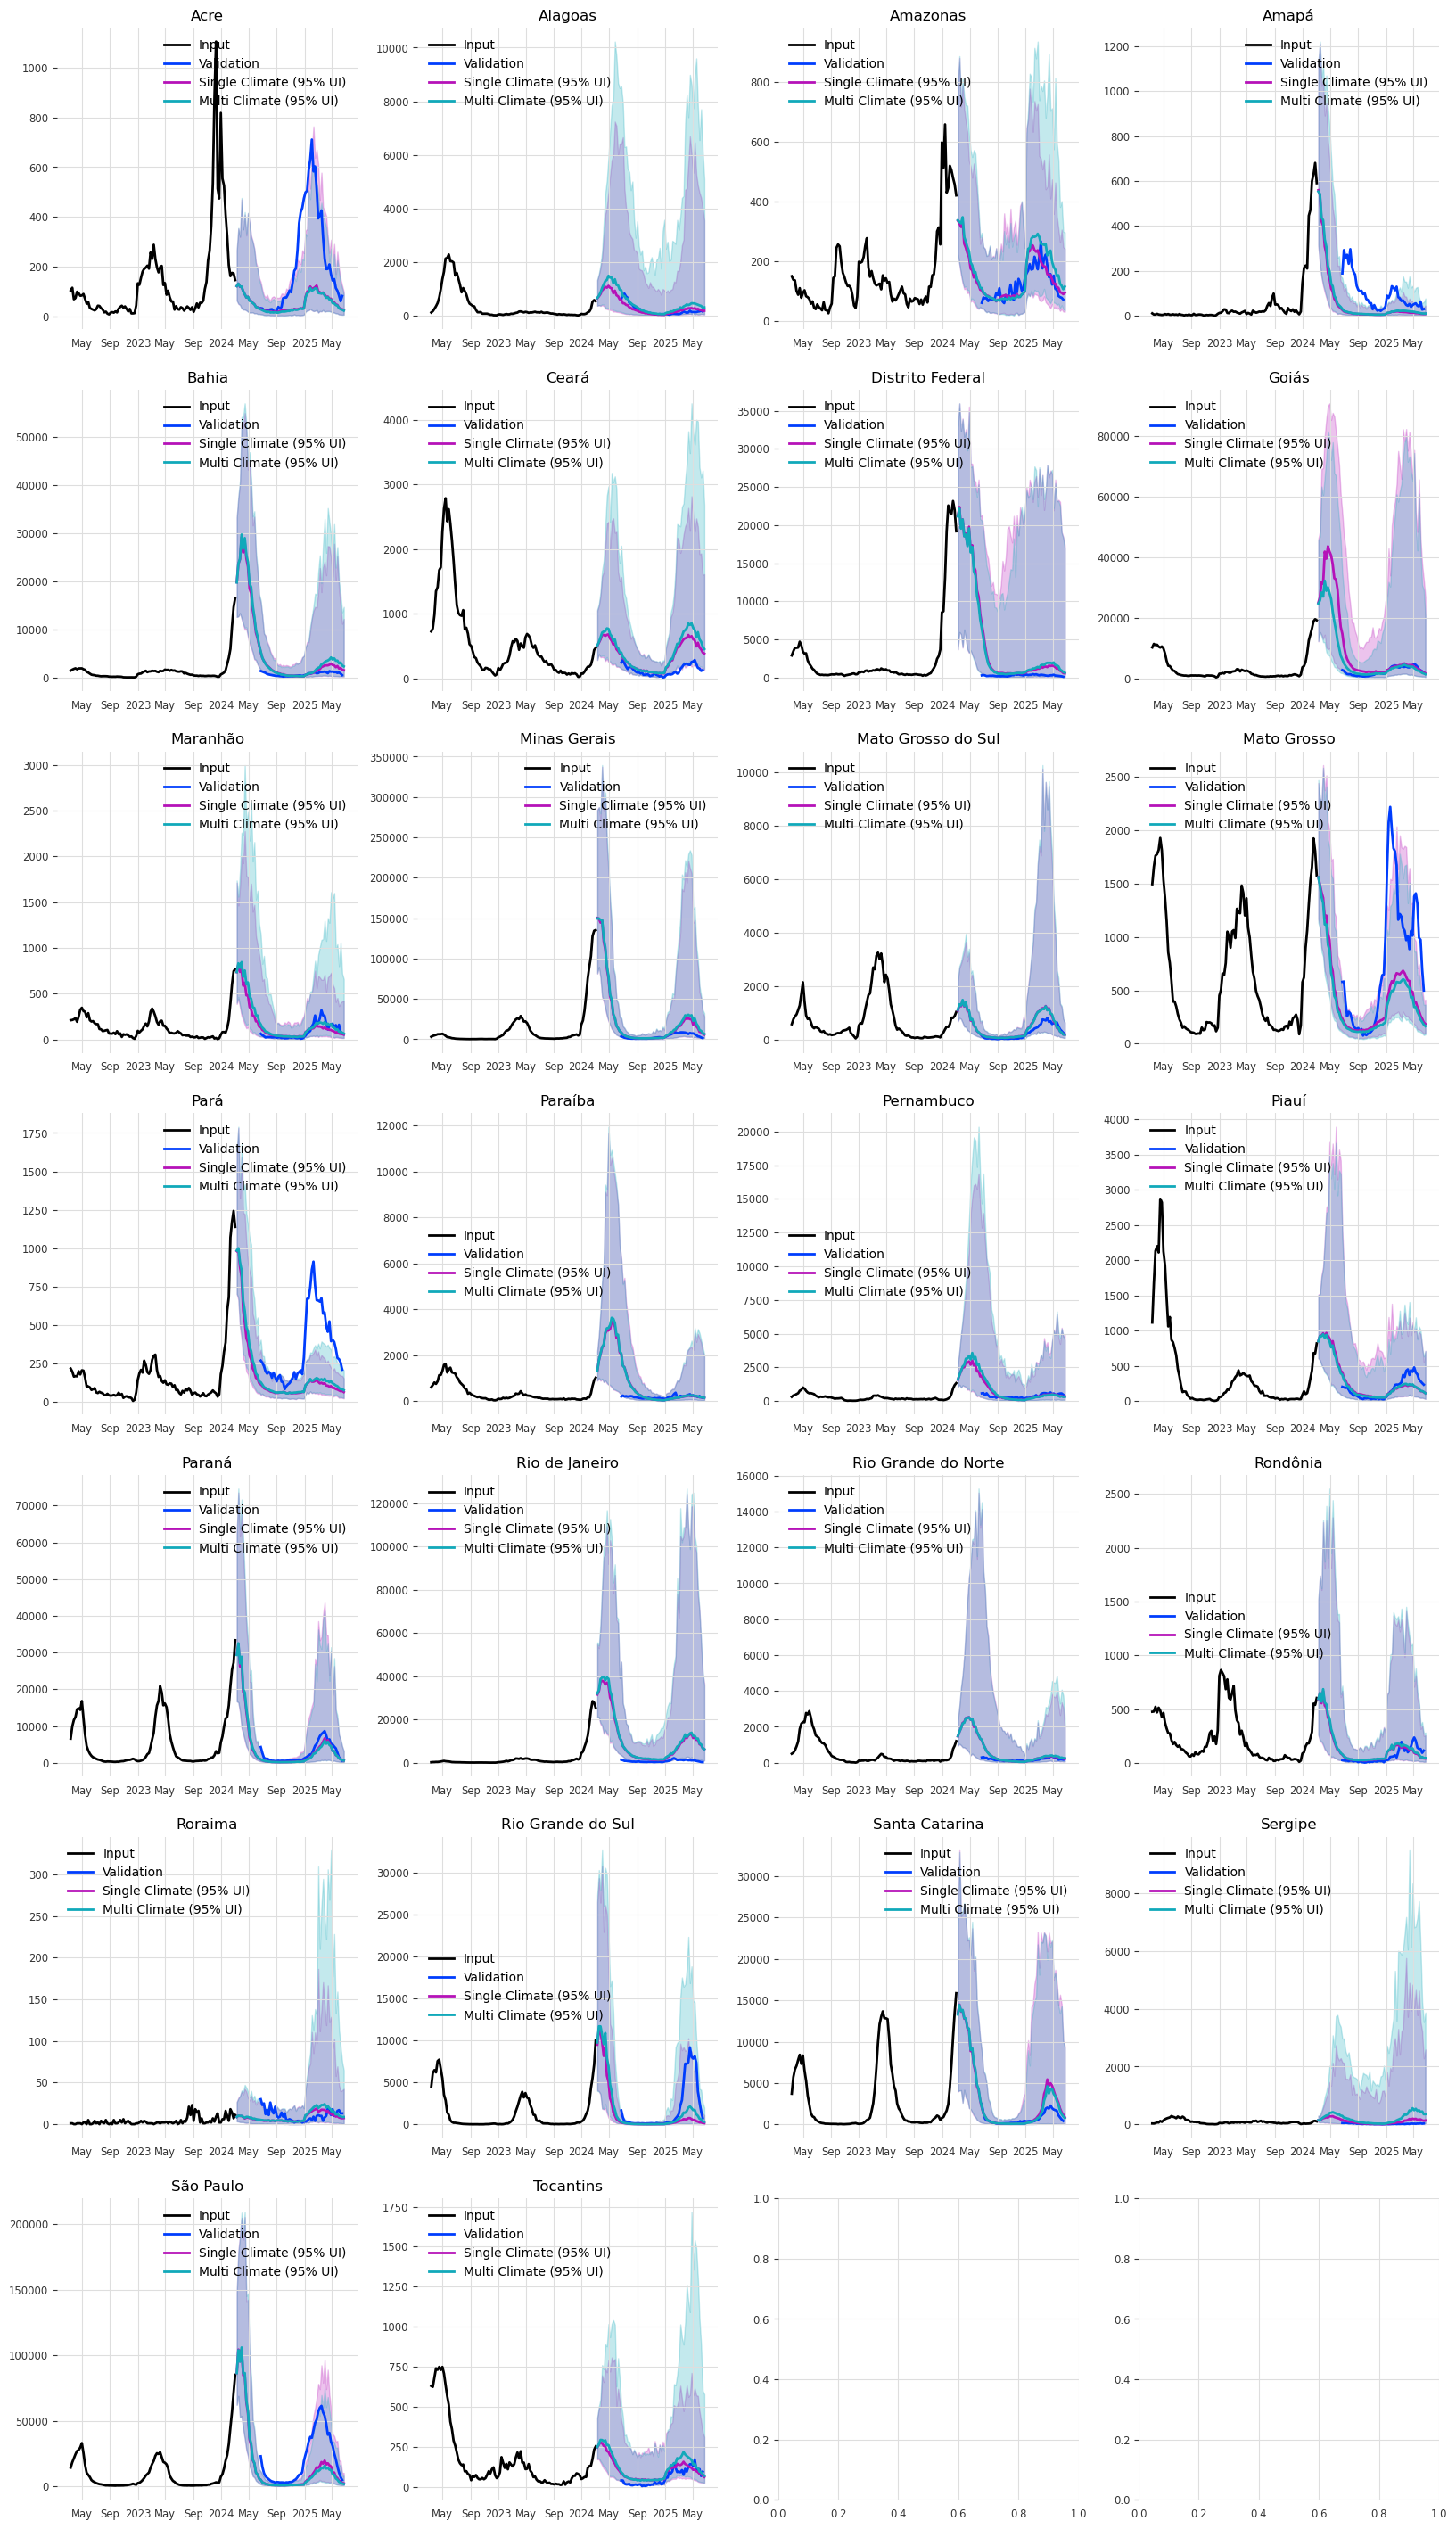

In [10]:
#Generate visuals of the Target 4 forecasts
val4_dict_list = hp.create_ts_dict_list([train4, val4, val4_preds_single, val4_preds_multi], 
                    ["Input", "Validation", "Single Climate (95% UI)", "Multi Climate (95% UI)"], uf_name_list, comp_name = None)
val4_plot = hp.plot_dict_list(val4_dict_list, limit_dict = {"Input": 104})
plt.savefig(os.path.join(vis_output_dir, "Val4_GlobalFit=" + str(global_fit) + "_TrainFromScratch=" + str(train_from_scratch) + "_MultiVersusSingleClimate.png"), dpi = 600, bbox_inches = "tight")

In [11]:
loss_val4_multi = hp.norm_metric_list(val4, val4_preds_multi, train1a, series_summ_func = np.mean, metric = mql, quantiles = quantiles)
loss_val4_single = hp.norm_metric_list(val4, val4_preds_single, train1a, series_summ_func = np.mean, metric = mql, quantiles = quantiles)

In [12]:
loss_val4_single
loss_val4_multi

0.16739040937578198

In [13]:
loss_val4_single

0.18512759665564635

In [24]:
curr_checker = targ4_preds_multi[8][15:]
curr_checker.median()

<TimeSeries (WeekStart: 53, component: 1, sample: 1)> Size: 424B
array([[[ 25.3761929 ]],

       [[ 24.07606741]],

       [[ 22.83500141]],

       [[ 21.81074174]],

       [[ 23.31949402]],

       [[ 21.03148385]],

       [[ 22.15918168]],

       [[ 22.84145495]],

       [[ 23.23348072]],

       [[ 23.63508356]],

...

       [[ 40.76599922]],

       [[ 34.5005618 ]],

       [[ 34.96832349]],

       [[ 28.78811715]],

       [[ 29.75422742]],

       [[ 24.60374699]],

       [[ 25.57784688]],

       [[ 26.7920506 ]],

       [[ 26.06403097]],

       [[ 26.85359967]]])
Coordinates:
  * WeekStart  (WeekStart) datetime64[ns] 424B 2025-10-05 ... 2026-10-04
  * component  (component) object 8B 'Cases'
Dimensions without coordinates: sample
Attributes:
    static_covariates:  static_covariates  koppen_Af  koppen_Am  koppen_As  k...
    hierarchy:          None
    metadata:           None

In [29]:
curr_checker.quantile(0.75)

<TimeSeries (WeekStart: 53, component: 1, sample: 1)> Size: 424B
array([[[ 37.8415105 ]],

       [[ 40.39201632]],

       [[ 40.20517726]],

       [[ 36.73319116]],

       [[ 39.99093411]],

       [[ 39.65582641]],

       [[ 41.61915601]],

       [[ 41.56621524]],

       [[ 40.72386475]],

       [[ 41.62147378]],

...

       [[ 64.51878983]],

       [[ 63.54250015]],

       [[ 53.4452164 ]],

       [[ 50.5001508 ]],

       [[ 43.70615814]],

       [[ 43.22961928]],

       [[ 43.2749866 ]],

       [[ 43.63324632]],

       [[ 43.24411492]],

       [[ 42.38200791]]])
Coordinates:
  * WeekStart  (WeekStart) datetime64[ns] 424B 2025-10-05 ... 2026-10-04
  * component  (component) object 8B 'Cases_q0.75'
Dimensions without coordinates: sample
Attributes:
    static_covariates:  static_covariates  koppen_Af  koppen_Am  koppen_As  k...
    hierarchy:          None
    metadata:           None